# Face Recognition – Metric Learning

This notebook trains a face embedding model using Triplet Loss.

The model is evaluated on the provided verification pairs using cosine similarity and Euclidean distance, then compared with the Classification baseline.

In [1]:
import os
import random
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

from PIL import Image
from tqdm.auto import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = PROJECT_ROOT / "11-785-fall-20-homework-2-part-2"
CLASSIFICATION_DIR = DATASET_DIR / "classification_data"
VERIFICATION_DIR = DATASET_DIR / "verification_data"

VAL_PAIRS_FILE = DATASET_DIR / "verification_pairs_val.txt"
TEST_PAIRS_FILE = DATASET_DIR / "verification_pairs_test.txt"

OUTPUT_DIR = PROJECT_ROOT / "runs" / "face_metric"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
IMAGE_SIZE = 224
EMBEDDING_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 2

LEARNING_RATE = 1e-4
EPOCHS = 20

# ImageNet normalization
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

## 1. Dataset Preparation

Load the provided face classification and verification datasets.

# Dataset Source:

# https://www.kaggle.com/c/11-785-fall-20-homework-2-part-2/overview/evaluation

In [2]:
# Dataset paths
DATASET_DIR = PROJECT_ROOT / "11-785-fall-20-homework-2-part-2"

CLASSIFICATION_DIR = DATASET_DIR / "classification_data"
VERIFICATION_DIR = DATASET_DIR / "verification_data"

VAL_PAIRS_FILE = DATASET_DIR / "verification_pairs_val.txt"
TEST_PAIRS_FILE = DATASET_DIR / "verification_pairs_test.txt"

# Output directory
OUTPUT_DIR = PROJECT_ROOT / "runs" / "face_metric"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_dir = CLASSIFICATION_DIR / "train_data"
val_dir = CLASSIFICATION_DIR / "val_data"
test_dir = CLASSIFICATION_DIR / "test_data"

# Verify dataset paths
assert DATASET_DIR.exists()
assert CLASSIFICATION_DIR.exists()
assert VERIFICATION_DIR.exists()
assert VAL_PAIRS_FILE.exists()
assert TEST_PAIRS_FILE.exists()

## 2. Load Classification Dataset

Load the training, validation, and test datasets using ImageFolder. Each class represents a different identity.

In [3]:
train_dataset = datasets.ImageFolder(train_dir)
val_dataset = datasets.ImageFolder(val_dir)
test_dataset = datasets.ImageFolder(test_dir)

num_classes = len(train_dataset.classes)

class_counts = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Identities": [
        len(train_dataset.classes),
        len(val_dataset.classes),
        len(test_dataset.classes)
    ],
    "Images": [
        len(train_dataset),
        len(val_dataset),
        len(test_dataset)
    ]
})

class_counts

,Dataset,Identities,Images
0,Train,4000,380638
1,Validation,4000,8000
2,Test,4000,8000


## 3. Image Preprocessing

Resize and normalize face images. Apply light data augmentation to the training dataset.

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

assert train_dataset.classes == val_dataset.classes
assert train_dataset.classes == test_dataset.classes

num_classes = len(train_dataset.classes)

## 4. DataLoader and Triplet Sampling

Use P-K sampling to ensure that each batch contains multiple images from the same identities.

In [5]:
from torch.utils.data import Sampler
import math
import random

class PKBatchSampler(Sampler):
    def __init__(self, dataset, identities_per_batch, images_per_identity, steps_per_epoch):
        self.identities_per_batch = identities_per_batch
        self.images_per_identity = images_per_identity
        self.steps_per_epoch = steps_per_epoch

        self.class_to_indices = {}

        for index, label in enumerate(dataset.targets):
            self.class_to_indices.setdefault(label, []).append(index)

        self.valid_classes = [
            label for label, indices in self.class_to_indices.items()
            if len(indices) >= images_per_identity
        ]

        assert len(self.valid_classes) >= identities_per_batch

    def __iter__(self):
        for _ in range(self.steps_per_epoch):
            selected_classes = random.sample(
                self.valid_classes,
                self.identities_per_batch
            )

            batch = []

            for label in selected_classes:
                selected_indices = random.sample(
                    self.class_to_indices[label],
                    self.images_per_identity
                )
                batch.extend(selected_indices)

            yield batch

    def __len__(self):
        return self.steps_per_epoch


# Training sampler
TRAIN_IDENTITIES_PER_BATCH = 8
TRAIN_IMAGES_PER_IDENTITY = 4
TRAIN_STEPS_PER_EPOCH = 1000

train_sampler = PKBatchSampler(
    train_dataset,
    identities_per_batch=TRAIN_IDENTITIES_PER_BATCH,
    images_per_identity=TRAIN_IMAGES_PER_IDENTITY,
    steps_per_epoch=TRAIN_STEPS_PER_EPOCH
)

# Validation sampler
VAL_IDENTITIES_PER_BATCH = 8
VAL_IMAGES_PER_IDENTITY = 2
VAL_STEPS_PER_EPOCH = math.ceil(
    len(val_dataset) /
    (VAL_IDENTITIES_PER_BATCH * VAL_IMAGES_PER_IDENTITY)
)

val_sampler = PKBatchSampler(
    val_dataset,
    identities_per_batch=VAL_IDENTITIES_PER_BATCH,
    images_per_identity=VAL_IMAGES_PER_IDENTITY,
    steps_per_epoch=VAL_STEPS_PER_EPOCH
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_sampler=train_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
)

val_loader = DataLoader(
    val_dataset,
    batch_sampler=val_sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
)

## 5. Embedding Model

Use a pretrained ResNet18 backbone to extract facial features and project them into a 128-dimensional embedding space.

In [6]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

in_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(in_features, EMBEDDING_SIZE),
    nn.BatchNorm1d(EMBEDDING_SIZE)
)

class FaceEmbeddingModel(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        embeddings = self.backbone(x)
        return F.normalize(embeddings, p=2, dim=1)


model = FaceEmbeddingModel(model).to(device)

## 6. Triplet Loss

Implement batch-hard Triplet Loss using the hardest positive and hardest negative samples within each batch.

In [7]:
def batch_hard_triplet_loss(embeddings, labels, margin=0.2):
    embeddings = embeddings.float()

    distances = torch.cdist(
        embeddings,
        embeddings,
        p=2
    )

    labels = labels.unsqueeze(0)

    positive_mask = labels.eq(labels.T)
    negative_mask = ~positive_mask

    positive_mask.fill_diagonal_(False)

    hardest_positive = distances.masked_fill(
        ~positive_mask,
        float("-inf")
    ).max(dim=1)[0]

    hardest_negative = distances.masked_fill(
        ~negative_mask,
        float("inf")
    ).min(dim=1)[0]

    loss = F.relu(
        hardest_positive - hardest_negative + margin
    )

    return loss.mean()

## 7. Model Training

Configure the optimizer, learning rate scheduler, mixed precision training, and checkpoint management.

In [8]:
EPOCHS = 20
LEARNING_RATE = 1e-4
MARGIN = 0.2

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=device.type == "cuda"
)

best_val_loss = float("inf")

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "learning_rate": [],
    "epoch_time": []
}

## 8. Training and Validation Functions

Train the embedding model using mixed precision and evaluate its Triplet Loss on the validation dataset.

In [9]:
def train_one_epoch(model, loader, optimizer, scaler):
    model.train()
    total_loss = 0.0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            embeddings = model(images)
            loss = batch_hard_triplet_loss(
                embeddings,
                labels,
                margin=MARGIN
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(loader)


@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()
    total_loss = 0.0

    progress = tqdm(loader, desc="Validation", leave=False)

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            embeddings = model(images)
            loss = batch_hard_triplet_loss(
                embeddings,
                labels,
                margin=MARGIN
            )

        total_loss += loss.item()
        progress.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(loader)

## 9. Training Execution

Train the face embedding model and save the best checkpoint based on validation Triplet Loss.

In [ ]:
checkpoint_path = OUTPUT_DIR / "latest.pt"

if checkpoint_path.exists():
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_loss = checkpoint["val_loss"]

    history_df = pd.read_csv(OUTPUT_DIR / "history.csv")
    history = history_df.to_dict(orient="list")
else:
    start_epoch = 1

for epoch in range(start_epoch, EPOCHS + 1):
    start_time = time.time()

    print(f"\nEpoch {epoch}/{EPOCHS}")

    train_loss = train_one_epoch(
        model, train_loader, optimizer, scaler
    )

    val_loss = validate_one_epoch(model, val_loader)

    scheduler.step(val_loss)

    epoch_time = time.time() - start_time
    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["learning_rate"].append(current_lr)
    history["epoch_time"].append(epoch_time)

    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / "history.csv",
        index=False
    )

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_loss,
        "embedding_size": EMBEDDING_SIZE,
        "classes": train_dataset.classes
    }

    torch.save(checkpoint, OUTPUT_DIR / "latest.pt")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(checkpoint, OUTPUT_DIR / "best.pt")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Learning Rate: {current_lr:.6f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

### 10. Visualise Training History

This cell visualises the training and validation loss across all epochs.

The loss curves help monitor the model's learning progress and identify potential overfitting. A decreasing validation loss indicates that the model is improving on unseen validation data.

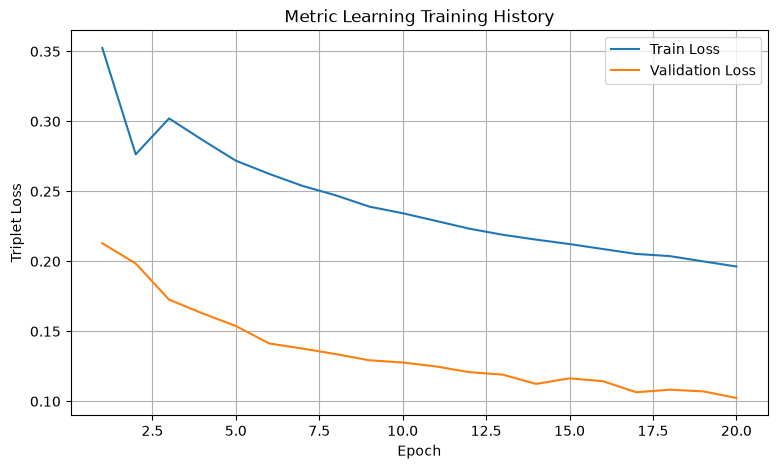

In [10]:
history_df = pd.read_csv(OUTPUT_DIR / "history.csv")

plt.figure(figsize=(9, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Triplet Loss")
plt.title("Metric Learning Training History")
plt.legend()
plt.grid(True)
plt.show()

### 11. Load Best Model

This cell loads the best model checkpoint saved during training.

Instead of using the model from the final epoch, we restore the checkpoint with the lowest validation loss. This helps ensure that the evaluation uses the best-performing version of the model.

In [11]:
checkpoint_path = OUTPUT_DIR / "best.pt"

backbone = models.resnet18(weights=None)
in_features = backbone.fc.in_features

backbone.fc = nn.Sequential(
    nn.Linear(in_features, EMBEDDING_SIZE),
    nn.BatchNorm1d(EMBEDDING_SIZE)
)

model = FaceEmbeddingModel(backbone).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")
print(f"Best validation loss: {checkpoint['val_loss']:.4f}")

Loaded checkpoint from epoch 20
Best validation loss: 0.1023


### 12. Load Verification Pairs

This cell loads the validation verification pairs from the dataset.

Each row contains two image paths and a label indicating whether the images belong to the same identity or different identities. These pairs will be used to evaluate the model's face verification performance.

In [12]:
VAL_PAIRS_FILE = DATASET_DIR / "verification_pairs_val.txt"

pairs_df = pd.read_csv(
    VAL_PAIRS_FILE,
    sep=r"\s+",
    header=None,
    names=["image1", "image2", "label"]
)

pairs_df["image1"] = pairs_df["image1"].apply(
    lambda x: str(DATASET_DIR / x)
)

pairs_df["image2"] = pairs_df["image2"].apply(
    lambda x: str(DATASET_DIR / x)
)

pairs_df.head()

,image1,image2,label
0,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0
1,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,1
2,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0
3,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,1
4,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0


### 13. Extract Face Embeddings

This cell extracts feature embeddings from all unique images in the verification pairs.

Each face image is passed through the trained model to obtain a 128-dimensional embedding. Extracting each unique image only once avoids redundant model inference and improves evaluation efficiency.

A DataLoader with single-process loading is used to improve compatibility with the Windows environment.

In [13]:
class VerificationImageDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        return self.transform(image), index


verification_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

unique_image_paths = sorted(
    set(pairs_df["image1"]).union(set(pairs_df["image2"]))
)

verification_dataset = VerificationImageDataset(
    unique_image_paths,
    verification_transform
)

verification_loader = DataLoader(
    verification_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=device.type == "cuda"
)

image_embeddings = {}

model.eval()

with torch.inference_mode():
    for images, indices in tqdm(
        verification_loader,
        desc="Extracting embeddings"
    ):
        images = images.to(device)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=device.type == "cuda"
        ):
            embeddings = model(images)

        embeddings = embeddings.float().cpu().numpy()

        for index, embedding in zip(indices.tolist(), embeddings):
            image_embeddings[unique_image_paths[index]] = embedding

Extracting embeddings:   0%|          | 0/147 [00:00<?, ?it/s]

### 14. Calculate Cosine Similarity and Euclidean Distance

This cell compares the embeddings of each verification pair using two distance metrics.

- Cosine Similarity: Higher values indicate greater similarity between two face embeddings.
- Euclidean Distance: Lower values indicate that two face embeddings are closer together.

Both metrics will be evaluated to determine how effectively they distinguish between matching and non-matching face pairs.

In [14]:
embedding1 = np.stack([
    image_embeddings[path] for path in pairs_df["image1"]
])

embedding2 = np.stack([
    image_embeddings[path] for path in pairs_df["image2"]
])

cosine_scores = np.sum(embedding1 * embedding2, axis=1)

euclidean_distances = np.linalg.norm(
    embedding1 - embedding2,
    axis=1
)

pairs_df["cosine_similarity"] = cosine_scores
pairs_df["euclidean_distance"] = euclidean_distances

pairs_df.head()

,image1,image2,label,cosine_similarity,euclidean_distance
0,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0,0.401059,1.094478
1,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,1,0.392223,1.102522
2,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0,-0.200585,1.549571
3,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,1,0.508187,0.991779
4,c:\Users\Helios\Documents\School Project\COS30...,c:\Users\Helios\Documents\School Project\COS30...,0,0.589322,0.906286


### 15. ROC Curve and ROC-AUC Evaluation

This cell evaluates the model using ROC curves and ROC-AUC scores.

ROC curves illustrate the trade-off between the True Positive Rate (TPR) and False Positive Rate (FPR) at different decision thresholds. ROC-AUC measures the model's ability to distinguish between matching and non-matching face pairs.

Both Cosine Similarity and Euclidean Distance are evaluated to compare their verification performance.

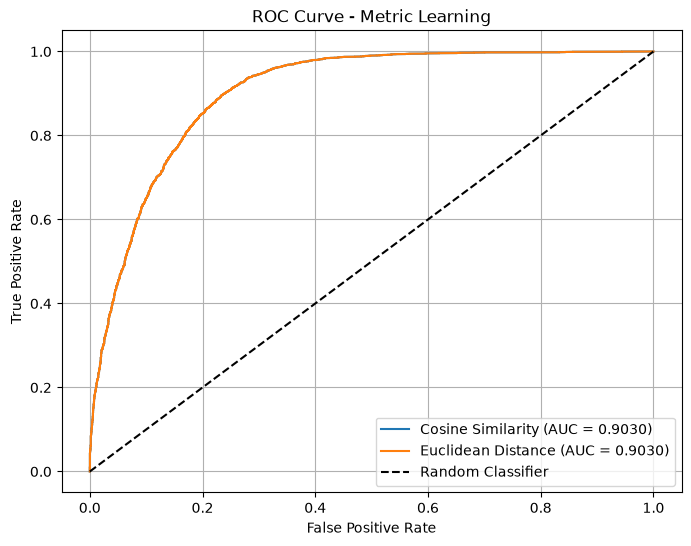

Cosine Similarity ROC-AUC: 0.9030
Euclidean Distance ROC-AUC: 0.9030


In [15]:
from sklearn.metrics import roc_curve, roc_auc_score

SAME_LABEL = 1

y_true = (pairs_df["label"] == SAME_LABEL).astype(int)

cosine_auc = roc_auc_score(y_true, cosine_scores)
euclidean_auc = roc_auc_score(y_true, -euclidean_distances)

cosine_fpr, cosine_tpr, _ = roc_curve(y_true, cosine_scores)
euclidean_fpr, euclidean_tpr, _ = roc_curve(y_true, -euclidean_distances)

plt.figure(figsize=(8, 6))

plt.plot(
    cosine_fpr,
    cosine_tpr,
    label=f"Cosine Similarity (AUC = {cosine_auc:.4f})"
)

plt.plot(
    euclidean_fpr,
    euclidean_tpr,
    label=f"Euclidean Distance (AUC = {euclidean_auc:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Metric Learning")
plt.legend()
plt.grid(True)
plt.show()

print(f"Cosine Similarity ROC-AUC: {cosine_auc:.4f}")
print(f"Euclidean Distance ROC-AUC: {euclidean_auc:.4f}")

### 16. Load Classification Verification Results

This cell loads the verification results generated by the classification-based model.

The saved verification metrics and pair scores will be used to compare the classification-based approach with the metric learning approach on the same validation verification pairs.

In [17]:
CLASSIFICATION_VERIFICATION_DIR = PROJECT_ROOT / "runs" / "face_classification" / "verification"
CLASSIFICATION_METRICS_FILE = CLASSIFICATION_VERIFICATION_DIR / "verification_metrics.json"

with open(CLASSIFICATION_METRICS_FILE, "r", encoding="utf-8") as f:
    classification_verification = json.load(f)

classification_verification

{'scope': 'validation only; threshold selected on these same pairs',
 'pairs': 8805,
 'target_calibration_fpr': 0.01,
 'checkpoint_sha256': 'de5902685c5a14aa58afd70ee6e2fbb54a92d717cbe7bffcc70da86b3b3a08f0',
 'pairs_sha256': '55ecf1495188024f414e3b0faac2b7f4cc374000a809e3b98579ecd8f4f25fdd',
 'metrics': {'cosine': {'roc_auc': 0.9065107732646513,
   'threshold': 0.48859700560569763,
   'tpr': 0.25469293163383544,
   'fpr': 0.009799554565701559,
   'accuracy': 0.629755820556502},
  'negative_euclidean': {'roc_auc': 0.9065108506866035,
   'threshold': -1.0113388299942017,
   'tpr': 0.25469293163383544,
   'fpr': 0.009799554565701559,
   'accuracy': 0.629755820556502}},
 'note': 'Pairwise thresholds require separate validation for 1:N gallery matching. No guaranteed webcam FPR.'}

### 17. Compare Verification Performance

This cell compares the verification performance of the classification-based model and the metric learning model.

Both approaches are evaluated using ROC-AUC scores from the validation verification pairs. The comparison includes Cosine Similarity and Euclidean Distance to determine which approach provides better face verification performance.

In [18]:
classification_results = classification_verification["metrics"]

comparison_rows = []

for metric_name, metric_label, metric_auc in [
    ("cosine_similarity", "Cosine Similarity", cosine_auc),
    ("euclidean_distance", "Euclidean Distance", euclidean_auc)
]:
    classification_metric = next(
        (
            values for key, values in classification_results.items()
            if metric_name in key.lower().replace("-", "_").replace(" ", "_")
            or (
                metric_name == "cosine_similarity"
                and "cosine" in key.lower()
            )
            or (
                metric_name == "euclidean_distance"
                and "euclidean" in key.lower()
            )
        ),
        None
    )

    if classification_metric is not None:
        classification_auc = classification_metric["roc_auc"]

        comparison_rows.append({
            "Distance Metric": metric_label,
            "Classification ROC-AUC": classification_auc,
            "Metric Learning ROC-AUC": metric_auc,
            "Difference": metric_auc - classification_auc
        })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df

,Distance Metric,Classification ROC-AUC,Metric Learning ROC-AUC,Difference
0,Cosine Similarity,0.906511,0.902953,-0.003557
1,Euclidean Distance,0.906511,0.902953,-0.003558


### 18. Visualise Model Comparison

This cell visualises the ROC-AUC comparison between the classification-based model and the metric learning model.

The bar chart provides a direct comparison of both approaches using Cosine Similarity and Euclidean Distance. Higher ROC-AUC values indicate better verification performance.

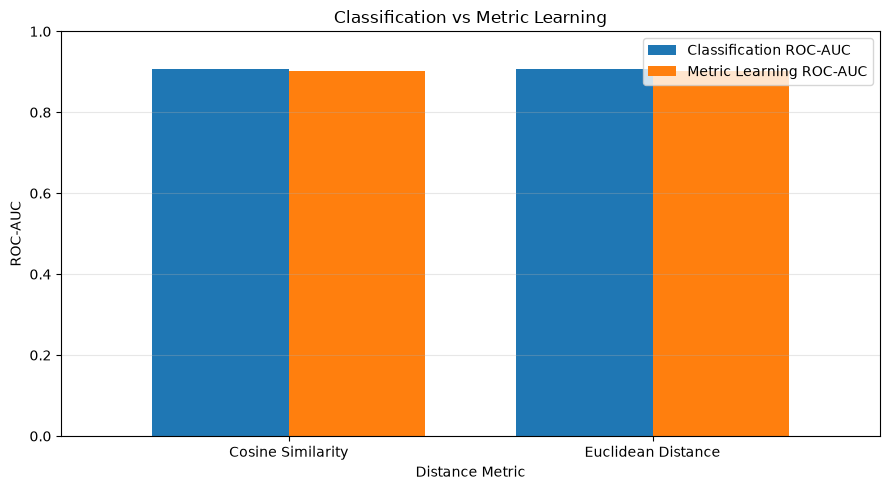

In [19]:
if not comparison_df.empty:
    comparison_plot = comparison_df.set_index("Distance Metric")[
        ["Classification ROC-AUC", "Metric Learning ROC-AUC"]
    ]

    comparison_plot.plot(
        kind="bar",
        figsize=(9, 5),
        ylim=(0, 1),
        width=0.75
    )

    plt.xlabel("Distance Metric")
    plt.ylabel("ROC-AUC")
    plt.title("Classification vs Metric Learning")
    plt.xticks(rotation=0)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 19. Save Metric Learning Verification Results

This cell saves the metric learning verification results for future reference.

The saved results include the ROC-AUC scores and the number of validation verification pairs. They can be used for reporting and further comparison without repeating the verification evaluation.

In [20]:
metric_learning_results = {
    "task": "face_verification",
    "model": "metric_learning",
    "split": "validation",
    "pairs": len(pairs_df),
    "metrics": {
        "cosine_similarity": {
            "roc_auc": float(cosine_auc)
        },
        "euclidean_distance": {
            "roc_auc": float(euclidean_auc)
        }
    }
}

with open(OUTPUT_DIR / "verification_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metric_learning_results, f, indent=4)

### 20. Final Discussion

The metric learning model was trained using Batch-Hard Triplet Loss to learn discriminative face embeddings.

The verification performance was evaluated using Cosine Similarity and Euclidean Distance, with ROC curves and ROC-AUC scores.

The results were compared with the classification-based model using the same validation verification pairs.

The comparison helps determine which approach provides better face verification performance and whether metric learning offers an improvement over the classification-based approach.